# 4. Etapa 2 – Analiza exploratorie în Python

## A. Incarcarea si curatarea tabelului evaluari

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
""" 1. Încarcă angajati_curat.csv, departamente.csv și evaluari.csv. Coloanele de
dată le citești direct ca dată: pd.read_csv('angajati_curat.csv',
parse_dates=['data_nasterii', 'data_angajarii', 'data_plecarii']).
Afișează pentru fiecare tabel: shape, info(), head()."""

angajati = pd.read_csv('angajati_curat.csv', parse_dates=['data_nasterii', 'data_angajarii', 'data_plecarii'])
departamente = pd.read_csv('departamente.csv')
evaluari = pd.read_csv('evaluari.csv')

def afiseaza(df, nume):
    print("\n" + "="*60)
    print(f"{nume}")
    print("="*60)
    print(f"Shape: {df.shape}\n")
    print(df.info())
    display(df.head())
    print("="*60)

afiseaza(angajati, "Angajati")
afiseaza(departamente, "Departamente")
afiseaza(evaluari, "Evaluari")




Angajati
Shape: (480, 21)

<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_angajat          480 non-null    int64         
 1   nume                480 non-null    str           
 2   prenume             480 non-null    str           
 3   gen                 480 non-null    str           
 4   data_nasterii       480 non-null    datetime64[us]
 5   data_angajarii      480 non-null    datetime64[us]
 6   id_departament      480 non-null    int64         
 7   functie             480 non-null    str           
 8   nivel               480 non-null    str           
 9   oras                480 non-null    str           
 10  tip_contract        480 non-null    str           
 11  salariu_brut_lunar  480 non-null    str           
 12  status              480 non-null    str           
 13  data_plecarii       115 non-null 

,id_angajat,nume,prenume,gen,data_nasterii,data_angajarii,id_departament,functie,nivel,oras,...,salariu_brut_lunar,status,data_plecarii,motiv_plecare,email,nume_departament,varsta,vechime_ani,grupa_vechime,plecat
0,1081,Voicu,Bianca,F,1980-06-09,2018-01-20,60,Manager Suport Clienți,Manager,București,...,"8,000",Plecat,2023-03-21,Relația cu managerul,bianca.voicu081@technova.ro,Suport Clienți,45,5.2,> 5 ani,1
1,1074,Nistor,Cristian,M,1998-03-08,2024-07-24,60,Operator Call Center,Mid,Timișoara,...,"4,100",Activ,NaT,NaN,cristian.nistor074@technova.ro,Suport Clienți,27,1.4,1–3 ani,0
2,1135,Voicu,Radu,M,1975-01-07,2018-05-28,70,Coordonator Logistică,Senior,București,...,"7,800",Activ,NaT,NaN,radu.voicu135@technova.ro,Operațiuni,50,7.6,> 5 ani,0
3,1473,Popescu,Florin,M,1993-09-21,2019-07-20,10,Tester QA,Junior,Cluj-Napoca,...,"6,100",Activ,NaT,NaN,florin.popescu473@technova.ro,IT,32,6.4,> 5 ani,0
4,1145,Constantin,Florin,M,1994-04-28,2022-09-04,10,Analist IT,Senior,București,...,"14,500",Activ,NaT,NaN,florin.constantin145@technova.ro,IT,31,3.3,3–5 ani,0



Departamente
Shape: (8, 4)

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   id_departament    8 non-null      int64
 1   nume_departament  8 non-null      str  
 2   oras_sediu        8 non-null      str  
 3   buget_anual_lei   8 non-null      int64
dtypes: int64(2), str(2)
memory usage: 388.0 bytes
None


,id_departament,nume_departament,oras_sediu,buget_anual_lei
0,10,IT,București,4200000
1,20,Vânzări,București,3100000
2,30,Marketing,Cluj-Napoca,1500000
3,40,Resurse Umane,București,900000
4,50,Financiar,Iași,1300000



Evaluari
Shape: (1149, 9)

<class 'pandas.DataFrame'>
RangeIndex: 1149 entries, 0 to 1148
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_evaluare              1149 non-null   int64  
 1   id_angajat               1149 non-null   int64  
 2   an_evaluare              1149 non-null   int64  
 3   scor_performanta         1119 non-null   float64
 4   satisfactie_angajat      1124 non-null   float64
 5   ore_suplimentare_lunare  1149 non-null   int64  
 6   ore_training_anual       1149 non-null   int64  
 7   zile_concediu_medical    1149 non-null   int64  
 8   procent_bonus            1149 non-null   float64
dtypes: float64(3), int64(6)
memory usage: 80.9 KB
None


,id_evaluare,id_angajat,an_evaluare,scor_performanta,satisfactie_angajat,ore_suplimentare_lunare,ore_training_anual,zile_concediu_medical,procent_bonus
0,1,1001,2023,3.0,6.0,2,35,5,4.9
1,4,1002,2023,4.0,6.0,0,36,4,7.0
2,7,1003,2023,3.0,NaN,9,40,9,4.8
3,9,1005,2023,3.0,4.0,16,2,8,5.5
4,12,1006,2023,5.0,7.0,0,15,5,12.5


##### Incarcarea fisierelor CSV
###### In acest pas am incarcat librariile necesare si cele trei fisiere: `angajati_curat.csv`, `departamente.csv` si `evaluari.csv`.  Pentru tabelul angajati, coloanele de data sunt convertite direct in format datetime folosind `parse_dates`, pentru a prelucra ulterior datele corect.  
###### Pentru fiecare tabel am afisat: `shape` (numarul de randuri si coloane), `info()` (tipurile de date si numarul de valori nenule), `head()` (primele 5 randuri), pentru a verifica incarcarea corecta si structura datelor.




In [3]:
"""2. Verifică în evaluari: duplicatele (duplicated()), valorile lipsă (isnull().sum()) și
valorile imposibile: scor_performanta în afara intervalului 1-5, satisfactie_angajat
în afara intervalului 1-10, ore_suplimentare_lunare peste 100."""

duplicate = evaluari.duplicated().sum()
print("Numar duplicate:", duplicate)

missing_values = evaluari.isnull().sum()
print("\nValori lipsa pe coloane:\n", missing_values)

nr_invalid_scor = ((evaluari['scor_performanta'] < 1) |
                   (evaluari['scor_performanta'] > 5)).sum()
print("\nScor performanta invalid:", nr_invalid_scor)

nr_invalid_satisfactie = ((evaluari['satisfactie_angajat'] < 1) |
                          (evaluari['satisfactie_angajat'] > 10)).sum()
print("Satisfactie angajat invalida:", nr_invalid_satisfactie)

nr_invalid_ore = (evaluari['ore_suplimentare_lunare'] > 100).sum()
print("Ore suplimentare lunare peste 100:", nr_invalid_ore)


Numar duplicate: 8

Valori lipsa pe coloane:
 id_evaluare                 0
id_angajat                  0
an_evaluare                 0
scor_performanta           30
satisfactie_angajat        25
ore_suplimentare_lunare     0
ore_training_anual          0
zile_concediu_medical       0
procent_bonus               0
dtype: int64

Scor performanta invalid: 4
Satisfactie angajat invalida: 3
Ore suplimentare lunare peste 100: 3


##### Rezumat verificari evaluari
###### In acest pas am verificat: cate duplicate exista, cate valori lipsa are fiecare coloana, cate valori imposibile exista pentru: scor_performanta (trebuie sa fie intre 1 si 5), satisfactie_angajat (trebuie sa fie intre 1 si 10), ore_suplimentare_lunare (nu trebuie sa depaseasca 100). Scopul acestei verificari este de a identifica erorile din date, pentru a le corecta ulterior.
###### Astfel, a rezultat ca sunt 8 duplicate, 30 valori lipsa pe coloana `scor_performanta`, 25 valori lipsa pe coloana `satisfactie_angajat`, 4 scoruri de performanta invalide, 3 valori invalide pentru satisfactia angajatilor, dar si 3 valori invalide pentru orele suplimentare lunare.



In [4]:
"""3. Elimină duplicatele și transformă valorile imposibile în valori lipsă (NaN). Apoi decide ce faci
cu toate valorile lipsă: cele care existau deja și cele create acum. Fie elimini rândurile, fie le
completezi cu mediana coloanei. Argumentează alegerea într-o celulă Markdown."""

evaluari = evaluari.drop_duplicates()

evaluari.loc[
    (evaluari['scor_performanta'] < 1) |
    (evaluari['scor_performanta'] > 5),
    'scor_performanta'
] = np.nan

evaluari.loc[
    (evaluari['satisfactie_angajat'] < 1) |
    (evaluari['satisfactie_angajat'] > 10),
    'satisfactie_angajat'
] = np.nan

evaluari.loc[
    evaluari['ore_suplimentare_lunare'] > 100,
    'ore_suplimentare_lunare'
] = np.nan

evaluari = evaluari.fillna(evaluari.median(numeric_only=True))


##### Tratarea valorilor lipsa
###### In acest pas am eliminat duplicatele din tabel, am transformat valorile imposibile in valori lipsa (NaN) si am decis cum tratez valorile lipsa: cele existente deja si cele create acum.
###### Pentru analiza bazei de date evaluari, valorile lipsa pot afecta calculele de medii si scoruri.  Astfel am ales sa completez valorile lipsa cu **mediana coloanei**, deoarece: mediana nu este influentata de valori extreme, pastreaza distributia naturala a datelor si evita pierderea de informatii prin eliminarea randurilor.



In [5]:
"""4. Verifică dacă există evaluări pentru id_angajat care nu apar în tabelul angajati (isin()).
Elimină-le și notează câte au fost; altfel importul în SQL nu va funcționa, din cauza cheii
străine."""

id_valide = angajati['id_angajat']

evaluari_invalid = evaluari[~evaluari['id_angajat'].isin(id_valide)]

nr_invalid = len(evaluari_invalid)
print("Numar evaluari cu id_angajat invalid:", nr_invalid)

evaluari = evaluari[evaluari['id_angajat'].isin(id_valide)]


Numar evaluari cu id_angajat invalid: 3


##### Verificarea evaluari
###### In acest pas am verificat daca exista evaluari pentru id_angajat care nu apare in tabelul angajati. Aceste randuri trebuie eliminate, altfel importul in SQL va esua din cauza cheii straine. Am folosit `isin()` pentru a identifica id-urile valide, astfel am identificat si eliminat 3 evaluari cu id_angajat invalid.


In [6]:
"""5. Salvează rezultatul în evaluari_curat.csv (to_csv(index=False))."""

evaluari.to_csv('evaluari_curat.csv', index=False)


##### Exportare CSV
###### In acest pas am exportat tabelul prelucrat `evaluari` intr-un fisier CSV nou, pentru a putea fi utilizat ulterior si importat in SQL.

## B. Intrebari la care trebuie sa raspunzi (cod + interpretare)

In [7]:
"""1. Care sunt media, mediana, minimul și maximul pentru salariu_brut_lunar, varsta și
vechime_ani?"""

# Salariul e citit ca text ("8,000"): am scos virgulele si am convertit la numeric
angajati['salariu_brut_lunar'] = pd.to_numeric(
    angajati['salariu_brut_lunar'].astype(str).str.replace(r'[",\s]', '', regex=True),
    errors='coerce'
)

coloane = ['salariu_brut_lunar', 'varsta', 'vechime_ani']

for col in coloane:
    print(f"\n=== {col} ===")
    print("Media:", angajati[col].mean().round().astype(int))
    print("Mediana:", angajati[col].median().round().astype(int))
    print("Minim:", angajati[col].min().round().astype(int))
    print("Maxim:", angajati[col].max().round().astype(int))



=== salariu_brut_lunar ===
Media: 6588
Mediana: 5950
Minim: 2300
Maxim: 18200

=== varsta ===
Media: 37
Mediana: 37
Minim: 21
Maxim: 56

=== vechime_ani ===
Media: 5
Mediana: 4
Minim: 0
Maxim: 10


##### Media, mediana, minimul si maximul pentru salariu, varsta si vechime
###### In urma analizei, am observat ca:
###### - Salariile variaza mult: de la 2,300 lei la 18,200 lei, cu o medie de ~6,600 lei. Exista diferente mari intre angajati, semn ca rolurile si nivelurile sunt foarte diverse.
###### - Varsta angajatilor este relativ concentrata: minim 21 ani, maxim 56 ani, mediana 37. Majoritatea angajatilor sunt in zona de mijloc a carierei.
###### - Vechimea variaza intre 0 si 10 ani, cu o medie de ~5 ani. Echipa are o combinatie de angajati noi si angajati cu experienta, dar nu exista vechimi extreme.


In [8]:
"""2. Care este rata de plecare generală și rata de plecare pe fiecare departament și pe fiecare
nivel? (media coloanei plecat, cu groupby)"""

rata_plecare_generala = angajati['plecat'].mean() * 100
print("Rata de plecare generală:", round(rata_plecare_generala, 2), "%")

print("\n=== Rata de plecare pe departament ===")
rata_plecare_departament = angajati.groupby('nume_departament')['plecat'].mean() * 100
print((rata_plecare_departament.round(2).astype(str) + " %"))

print("\n=== Rata de plecare pe nivel ===")
rata_plecare_nivel = angajati.groupby('nivel')['plecat'].mean() * 100
print((rata_plecare_nivel.round(2).astype(str) + " %"))

Rata de plecare generală: 23.96 %

=== Rata de plecare pe departament ===
nume_departament
Financiar         19.44 %
IT                16.07 %
Juridic            25.0 %
Marketing         23.26 %
Operațiuni        16.46 %
Resurse Umane      12.0 %
Suport Clienți    31.76 %
Vânzări           39.29 %
Name: plecat, dtype: str

=== Rata de plecare pe nivel ===
nivel
Junior     29.94 %
Manager    17.14 %
Mid        20.69 %
Senior     22.81 %
Name: plecat, dtype: str


##### Rata de plecare generala, rata de plecare pe fiecare departament si pe fiecare nivel
###### Rata de plecare generala este de ~24%, ceea ce indică un nivel moderat de fluctuatie în organizatie.
###### Departamentele cu cele mai mari rate de plecare sunt: Vanzari (39%) si Suport Clienti (32%). Aceste zone au cea mai mare instabilitate si necesita atentie.
###### Departamentele cu cele mai mici rate de plecare sunt: Resurse Umane (12%) si IT (16%). Sunt echipe stabile, cu retentie buna.
###### Pe niveluri, plecarea este cea mai ridicata la: Juniori (30%), ceea ce inseamna ca angajatii aflati la inceput de cariera sunt cei mai predispusi sa plece.
###### Managerii au cea mai mica rata de plecare (17%), ceea ce arata stabilitate la nivel de conducere.


In [9]:
"""3. Calculează, pentru fiecare angajat, media evaluărilor lui din toți anii
(groupby('id_angajat').mean()), pentru: satisfacție, ore suplimentare, performanță,
ore de training și procent bonus. Unește rezultatul cu tabelul angajati: merge(...,
on='id_angajat', how='left'). Apoi compară angajații plecați cu cei activi într-un
tabel (groupby('status').mean()), pe aceste coloane și pe salariu și vechime. Ce
diferențe observi? (Unii angajați plecați înainte de 2023 nu au evaluări: e normal să aibă
valori lipsă.)"""

coloane_eval = [
    'id_angajat',
    'satisfactie_angajat',
    'ore_suplimentare_lunare',
    'scor_performanta',
    'ore_training_anual',
    'procent_bonus'
]

evaluari_select = evaluari[coloane_eval]

media_eval = evaluari_select.groupby('id_angajat').mean()

angajati_eval = angajati.merge(media_eval, on='id_angajat', how='left')

comparatie = angajati_eval.groupby('status')[[
    'satisfactie_angajat',
    'ore_suplimentare_lunare',
    'scor_performanta',
    'ore_training_anual',
    'procent_bonus',
    'salariu_brut_lunar',
    'vechime_ani'
]].mean()

comparatie

,satisfactie_angajat,ore_suplimentare_lunare,scor_performanta,ore_training_anual,procent_bonus,salariu_brut_lunar,vechime_ani
status,,,,,,,
Activ,6.568037,7.218721,3.561644,23.438813,6.775799,6776.506849,5.163288
Plecat,5.997653,10.457746,3.612676,25.946009,6.989671,5990.652174,2.573043


##### Media evaluarilor pe angajat si comparatie intre angajatii activi si plecati
###### In acest pas am folosit tabelul evaluari pentru a calcula media evaluarilor pe fiecare angajat: satisfactie, ore suplimentare, performanta, ore de training anual si procent bonus. Apoi am unit aceste rezultate cu tabelul angajati printr-un merge pe `id_angajat`. La final am comparat angajatii activi cu cei plecati pentru a observa diferentele pe acesti indicatori, plus salariu si vechime. Este normal ca angajatii plecati inainte de 2023 sa nu aiba evaluari, deci apar valori lipsa.
###### In urma comparatiei, am observat ca:
###### -  angajatii activi au un nivel de satisfactie mai mare, in medie 6.57, in timp ce angajatii plecati au o satisfactie medie de 5.99
###### - angajatii plecati au lucrat mai multe ore suplimentare lunar, avand o medie de 10.46 ore, fata de 7.22 ore la angajatii activi
###### - scorul de performanta este foarte apropiat intre cele doua grupuri, activii avand 3.56, iar plecatii 3.61.
###### - angajatii plecati au beneficiat de mai multe ore de training anual, cu o medie de 25.95 ore, fata de 23.44 ore la angajatii activi
###### - procentul de bonus este usor mai mare la angajatii plecati, cu o medie de 6.99%, comparat cu 6.78% la angajatii activi
###### - angajatii activi au salarii brute lunare mai mari, in medie 6,776 lei, fata de 5,991 lei la angajatii plecati
###### - angajatii activi au o vechime semnificativ mai mare, in medie 5.16 ani, in timp ce angajatii plecati au doar 2.57 ani.




In [10]:
"""4. Care sunt cele mai frecvente 3 motive de plecare? (value_counts() pe angajații plecați)"""

plecati = angajati[angajati['plecat'] == 1]

top_motive = plecati['motiv_plecare'].value_counts().head(3)

print("=== Top 3 motive de plecare ===\n")
for motiv, nr in top_motive.items():
    print(f"- {motiv}: {nr} angajati")

=== Top 3 motive de plecare ===

- Salariu mai bun în altă parte: 31 angajati
- Echilibru viață-muncă: 24 angajati
- Lipsa oportunităților de promovare: 18 angajati


##### Cele mai frecvente 3 motive de plecare
###### Din totalul angajaților plecați, cele mai frecvente 3 motive de plecare sunt: salariul mai bun in alta parte pentru 31 de angajati, echilibrul viata-munca pentru 24 de angajati, iar pentru 18 angajati, lipsa oportunitatilor de promovare a fost motivul principal al demisiei.

In [11]:
"""5. Pe tabelul unit de la întrebarea 3, construiește matricea de corelație (corr()) pentru:
salariu, vârstă, vechime, plecat, satisfacție, ore suplimentare, performanță, training și bonus.
Care sunt cele mai puternice 3 corelații și ce înseamnă ele? Ignoră diagonala (valorile de 1)
și perechile repetate. Compară după valoarea absolută, pentru că și o corelație negativă
mare (ex: -0,4) contează. Coloana plecat fiind 0/1, corelațiile ei arată ce factori sunt
asociați cu plecarea."""

coloane = [
    'salariu_brut_lunar',
    'varsta',
    'vechime_ani',
    'plecat',
    'satisfactie_angajat',
    'ore_suplimentare_lunare',
    'scor_performanta',
    'ore_training_anual',
    'procent_bonus'
]

corr_matrix = angajati_eval[coloane].corr()

print("=== Matricea de corelatie ===")
print(corr_matrix.round(3))

corr_pairs = corr_matrix.unstack()
corr_pairs = corr_pairs[corr_pairs != 1]
corr_pairs = corr_pairs.drop_duplicates()

top3 = corr_pairs.abs().sort_values(ascending=False).head(3)

print("\n=== Top 3 corelatii ===")
for (c1, c2), val in top3.items():
    print(f"- {c1} ↔ {c2}: {val:.3f}")



=== Matricea de corelatie ===
                         salariu_brut_lunar  varsta  vechime_ani  plecat  \
salariu_brut_lunar                    1.000   0.291        0.033  -0.112   
varsta                                0.291   1.000        0.032  -0.068   
vechime_ani                           0.033   0.032        1.000  -0.392   
plecat                               -0.112  -0.068       -0.392   1.000   
satisfactie_angajat                   0.181   0.042        0.066  -0.125   
ore_suplimentare_lunare              -0.078   0.062       -0.035   0.212   
scor_performanta                      0.117   0.043       -0.064   0.032   
ore_training_anual                   -0.131  -0.047       -0.079   0.090   
procent_bonus                         0.107   0.061       -0.043   0.038   

                         satisfactie_angajat  ore_suplimentare_lunare  \
salariu_brut_lunar                     0.181                   -0.078   
varsta                                 0.042                   

##### Matricea de corelatie
###### Ce am facut:
###### - Am folosit tabelul unit de la intrebarea 3 (angajati + mediile evaluarilor)
###### - Am selectat variabilele numerice relevante: salariu, varsta, vechime, plecat, satisfactie, ore suplimentare, performanta, training si bonus
###### - Am construit matricea de corelatie si am identificat cele mai puternice 3 corelatii, ignorând diagonala si perechile duplicate
###### - Am comparat corelatiile dupa valoarea absoluta, pentru a include si relatiile negative puternice.
###### Cele mai puternice 3 corelatii:
###### 1. Scor performanta ↔ Procent bonus: 0.925 - Corelatie extrem de puternica. Angajatii cu performanta mai mare primesc bonusuri semnificativ mai mari. Sistemul de bonus pare strans legat de evaluarile de performanta.
###### 2. Vechime ↔ Plecat: 0.392 - Corelatie pozitiva moderata. Angajatii cu vechime mai mare au o probabilitate mai ridicata sa fi plecat. Poate indica stagnare, burnout sau oportunitati externe mai bune pentru cei cu experienta.
###### 3. Salariu ↔ VVarsta: 0.291 - Corelatie pozitiva slab-moderata. Angajatii mai in varsta tind sa aiba salarii mai mari, ceea ce este normal: experienta mai mare rezulta in pozitii mai bine platite.
###### Concluzii:
###### - Bonusurile sunt aproape perfect aliniate cu performanta
###### - Angajatii cu vechime mai mare sunt mai predispuși sa plece  
###### - Salariile cresc odata cu varsta, dar relatia nu este foarte puternica.


In [12]:
"""6. Câte angajări și câte plecări au fost în fiecare an, 2016-2025? Angajările se numără după
anul din data_angajarii, iar plecările după anul din data_plecarii (dt.year +
value_counts()). Pune rezultatul într-un tabel cu două coloane: angajari și plecari."""

angajati['an_angajare'] = angajati['data_angajarii'].dt.year
angajati['an_plecare'] = angajati['data_plecarii'].dt.year

angajari = angajati['an_angajare'].value_counts().sort_index()

plecari = angajati['an_plecare'].value_counts().sort_index()

tabel_ani = pd.DataFrame({
    'angajari': angajari,
    'plecari': plecari
}).fillna(0).astype(int)

tabel_ani.index = tabel_ani.index.astype(int) # pentru a elimina eventualele zecimale din index

print("=== Angajari si plecari pe ani (2016-2025) ===")
print(tabel_ani)

=== Angajari si plecari pe ani (2016-2025) ===
      angajari  plecari
2016        45        0
2017        58        1
2018        51        7
2019        47        3
2020        51        7
2021        43       11
2022        52       15
2023        51       21
2024        47       11
2025        35       39


##### Angajari si plecari pe ani (2016-2025)
###### Ce am facut
###### - Am extras anul din `data_angajarii` si `data_plecarii`
###### - Am numarat angajarile si plecarile pentru fiecare an
###### - Am pus rezultatele intr-un tabel cu doua coloane: angajari si plecari
###### - Am convertit indexul anilor la format integer pentru afisare corecta.

###### Interpretare:
###### - Angajarile sunt relativ stabile, intre 43 si 58 pe an
###### - Plecarile cresc constant: de la 0-3 in 2016-2019, la 21 in 2023
###### - In 2025 apare un varf major: 39 plecari, cel mai mare din toata perioada
###### - In 2025 plecarile depasesc angajarile (35 vs 39), indicand pierdere neta de personal.

###### Organizatia este stabila pana in 2022, dar 2023-2025 arata o crestere clara a plecarilor, culminand cu un varf in 2025.


## C. Grafice obligatorii

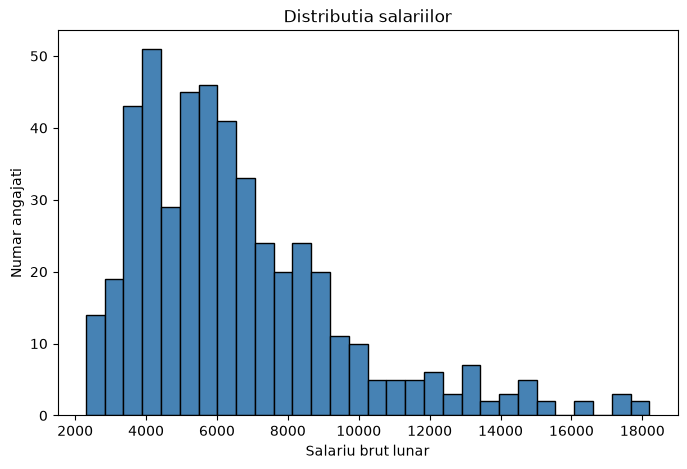

In [13]:
"""G1 - Histograma: Distributia salariilor"""

plt.figure(figsize=(8,5))
plt.hist(angajati['salariu_brut_lunar'], bins=30, color='steelblue', edgecolor='black')
plt.title("Distributia salariilor")
plt.xlabel("Salariu brut lunar")
plt.ylabel("Numar angajati")
plt.show()


##### Concluzii G1 - Distributia salariilor

###### - Majoritatea angajatilor au salarii intre aproximativ 3,000 si 7,000
###### - Distributia este puternic concentrata in zona salariilor mici si medii
###### - Salariile mari sunt rare, frecventa scade rapid dupa ~8,000
###### - Forma este clar right-skewed: putini angajati castiga mult, multi castiga putin sau mediu.

###### Pe scurt, structura salariala este dezechilibrata: organizatia are o baza larga de angajati cu salarii mici/medii si foarte putini cu salarii ridicate. Acest lucru poate indica o piramida organizationala clasica, cu multe roluri operationale si putine roluri senior/manageriale.


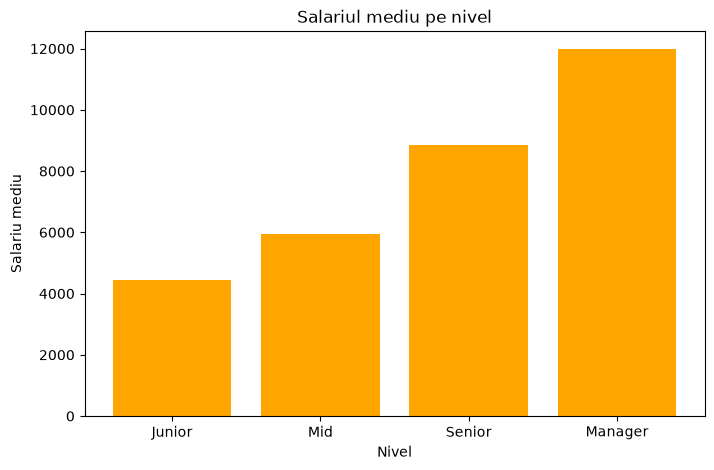

In [14]:
"""G2 - Bar chart: Salariul mediu pe nivel"""

ordine = ["Junior", "Mid", "Senior", "Manager"]
salarii_nivel = angajati.groupby('nivel')['salariu_brut_lunar'].mean().reindex(ordine)

plt.figure(figsize=(8,5))
plt.bar(salarii_nivel.index, salarii_nivel.values, color='orange')
plt.title("Salariul mediu pe nivel")
plt.xlabel("Nivel")
plt.ylabel("Salariu mediu")
plt.show()


##### Concluzii G2 - Salariul mediu pe nivel

###### - Salariul creste clar si ordonat pe masura ce nivelul profesional avanseaza
###### - Junior are cel mai mic salariu mediu (~4,500), ceea ce reflecta roluri entry-level
###### - Mid urca spre ~6,000, semn ca experienta aduce o crestere moderata
###### - Senior ajunge la ~9,000, o crestere semnificativa fata de Mid
###### - Manager depaseste ~12,000, fiind cel mai bine platit nivel.

###### Structura salariala este bine aliniata cu nivelul de senioritate: fiecare treapta aduce o crestere consistenta. Diferentele sunt mari intre Senior si Manager, ceea ce indica o recompensa puternica pentru rolurile de conducere.


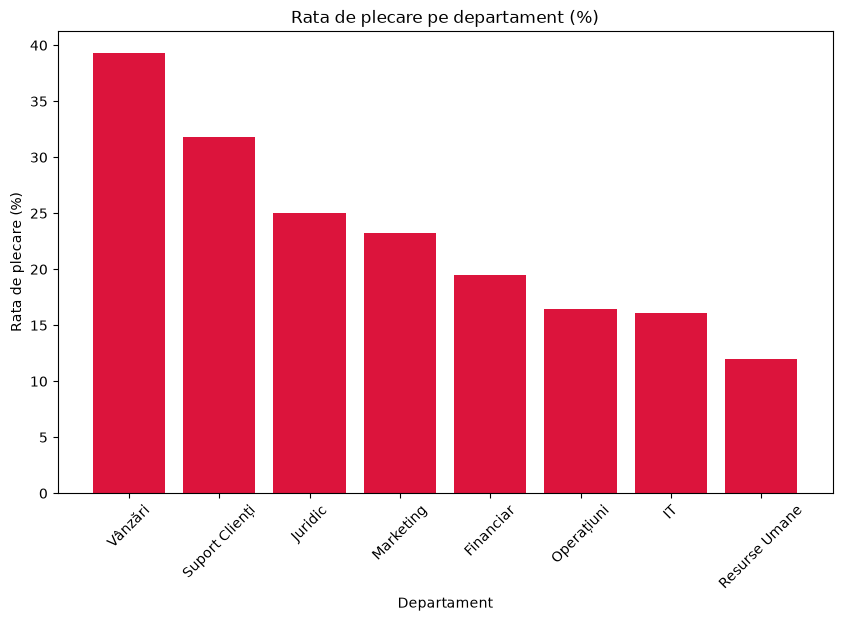

In [15]:
"""G3 - Bar chart: Rata de plecare pe departament (%)"""

rata_depart = (angajati.groupby('nume_departament')['plecat'].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(10,6))
plt.bar(rata_depart.index, rata_depart.values, color='crimson')
plt.title("Rata de plecare pe departament (%)")
plt.xlabel("Departament")
plt.ylabel("Rata de plecare (%)")
plt.xticks(rotation=45)
plt.show()


##### Concluzii G3 - Rata de plecare pe departament (%)

###### - Departamentul Vanzari are cea mai mare rata de plecare, aproape de 40%. Este zona cu cea mai mare fluctuatie si probabil cel mai mare nivel de stres sau presiune pe rezultate
###### - Suport Clienti si Juridic au rate ridicate, semn ca rolurile sunt solicitante sau pot avea volum mare de lucru
###### - Marketing, Financiar si Operatiuni sunt la nivel mediu, cu plecari moderate
###### - IT si Resurse Umane au cele mai mici rate de plecare, sub 20%, indicand stabilitate mai mare si retentie buna.

###### Fluctuatia este puternic concentrata in departamentele orientate spre clienti si rezultate (Vanzari, Suport). Departamentele IT si HR sunt mult mai stabile. Acest pattern este tipic pentru organizatii unde presiunea comerciala genereaza rotatie mai mare.


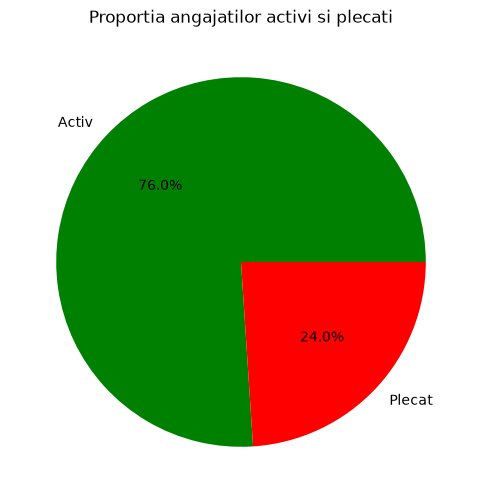

In [16]:
"""G4 - Pie chart: Activ vs plecat"""

status_counts = angajati['status'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(status_counts.values, labels=status_counts.index, autopct='%1.1f%%', colors=['green','red'])
plt.title("Proportia angajatilor activi si plecati")
plt.show()

##### Concluzii G4 - Proportia angajatilor activi si plecati

###### - 76% dintre angajati sunt activi, ceea ce arata o retentie buna la nivel general
###### - 24% sunt plecati, o proportie moderata, dar nu alarmanta
###### - Raportul activ vs plecat este aproximativ 3:1, ceea ce indica stabilitate in organizatie.

###### Putem spune ca majoritatea angajatilor raman in companie, iar plecarile sunt relativ controlate. Totusi, procentul de 24% plecati nu este neglijabil si merita analizat pe departamente si ani pentru a intelege unde apar problemele de retentie.


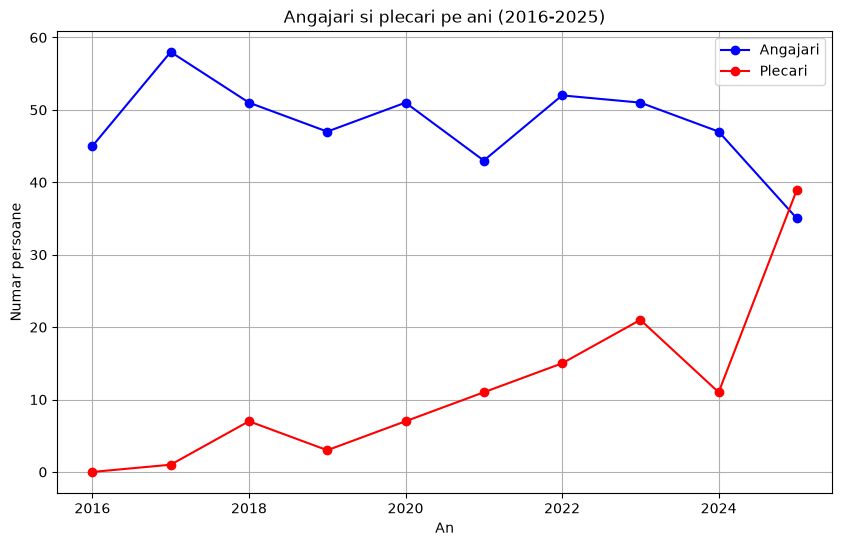

In [17]:
"""G5 - Line chart: Angajari si plecari pe ani"""

plt.figure(figsize=(10,6))
plt.plot(tabel_ani.index, tabel_ani['angajari'], marker='o', label='Angajari', color='blue')
plt.plot(tabel_ani.index, tabel_ani['plecari'], marker='o', label='Plecari', color='red')

plt.title("Angajari si plecari pe ani (2016-2025)")
plt.xlabel("An")
plt.ylabel("Numar persoane")
plt.legend()
plt.grid(True)
plt.show()

##### Concluzii G5 - Angajari si plecari pe ani (2016-2025)

###### Observatii principale:
###### - Angajarile sunt relativ stabile in intervalul 2016-2024, in general intre 45 si 55 pe an
###### - Plecarile cresc constant: de la aproape 0 in 2016 la aproape 40 in 2025
###### - In 2025 apare ruptura majora: plecarile (39) depasesc angajarile (35), ceea ce indica pierdere neta de personal
###### - Diferenta dintre angajari si plecari se reduce treptat, semn ca retentia se deterioreaza in timp.

###### In concluzie, organizatia a fost stabila pana in 2022, dar 2023-2025 arata o tendinta clara de crestere a plecarilor. Varful din 2025 sugereaza probleme de retentie, presiune crescuta sau schimbari interne majore. Trendul este ingrijorator si merita investigat pe departamente si niveluri.
